# 10 – ABSA 4 khía cạnh và phân tích kinh doanh (P5 kết quả ABSA, P6 top 3 vấn đề)

**ABSA bằng từ điển + mô hình cảm xúc** (`src/aspects.py`):
1. Chuẩn hóa văn bản (chưa tách từ) và tách thành mệnh đề theo dấu câu và các từ "nhưng", "mà", "tuy".
2. Mệnh đề chứa từ khóa của khía cạnh nào thì thuộc khía cạnh đó.
3. Chạy mô hình cảm xúc (TF-IDF+LR, A+B) trên **mệnh đề**, không chạy trên cả câu.

Vì sao không học ABSA từ ViSD4SA: ViSD4SA không có khía cạnh giao hàng (chỉ 51 review nhắc tới), và chỉ gồm điện thoại. Hướng mở rộng: huấn luyện bộ phân loại riêng cho từng khía cạnh trên các cột `chat_luong`, `gia_ca`, `dich_vu` của ViSD4SA.

In [1]:
import sys, os, joblib
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, precision_recall_fscore_support
from src.data import load_gold, load_category, ASPECTS, P
from src.aspects import absa, detect_aspects, ASPECT_KEYWORDS
from src.preprocess import preprocess

FIG, REP, MOD = "../figures", "../report", "../models"
model = joblib.load(f"{MOD}/tfidf_lr_AB.joblib")
ASP_VI = {"giao_hang": "Giao hàng", "chat_luong": "Chất lượng", "gia_ca": "Giá cả", "dich_vu": "Dịch vụ"}

t = "Ship nhanh, đóng gói cẩn thận nhưng chất liệu vải hơi mỏng, giá thì rẻ. Shop tư vấn nhiệt tình"
print(detect_aspects(preprocess(t, segment=False)))
print(absa(t, model))

{'giao_hang': ['giao hàng nhanh', 'đóng gói cẩn thận'], 'chat_luong': ['nhưng chất liệu vải hơi mỏng'], 'gia_ca': ['giá thì rẻ'], 'dich_vu': ['cửa hàng tư vấn nhiệt tình']}


{'giao_hang': 'pos', 'chat_luong': 'neu', 'gia_ca': 'pos', 'dich_vu': 'pos'}


## 1. Đánh giá ABSA trên các câu đã gán khía cạnh

- **Phát hiện khía cạnh**: câu có nhắc tới khía cạnh không (nhãn tay khác `none`). Báo Precision, Recall, F1.
- **Cảm xúc khía cạnh**: accuracy trên những khía cạnh phát hiện đúng.

In [2]:
gold, GOLD_TEMP = load_gold()
if GOLD_TEMP or "gan_khia_canh" not in gold or gold[ASPECTS].notna().sum().sum() == 0:
    print("Chưa có nhãn khía cạnh tay. Gán xong 150 câu khía cạnh rồi chạy lại ô này.")
    absa_eval = None
else:
    ga = gold[(gold.gan_khia_canh == "có") & gold[ASPECTS].notna().all(axis=1)].copy()
    pred = ga.text_raw.map(lambda s: absa(s, model))
    rows = []
    for a in ASPECTS:
        true_has = ga[a] != "none"
        pred_lab = pred.map(lambda d: d.get(a, "none"))
        p, r, f, _ = precision_recall_fscore_support(true_has, pred_lab != "none", average="binary", zero_division=0)
        both = true_has & (pred_lab != "none")
        rows.append({"Khía cạnh": ASP_VI[a], "Số câu có nhắc": int(true_has.sum()),
                     "Precision phát hiện": p, "Recall phát hiện": r, "F1 phát hiện": f,
                     "Acc cảm xúc (phát hiện đúng)": (ga[a][both] == pred_lab[both]).mean() if both.any() else np.nan})
    absa_eval = pd.DataFrame(rows).round(3)
    absa_eval.to_csv(f"{REP}/absa_eval.csv", index=False, encoding="utf-8-sig")
    print(len(ga), "câu có nhãn khía cạnh")
    display(absa_eval)

Chưa có nhãn khía cạnh tay. Gán xong 150 câu khía cạnh rồi chạy lại ô này.


**Tự kiểm tra:** Khía cạnh nào Recall thấp? Mở những câu bị bỏ sót và bổ sung từ khóa vào `ASPECT_KEYWORDS`. Cẩn thận: chỉ dùng câu **ngoài** tập vàng để tìm từ khóa, nếu không thì đánh giá bị lạc quan giả.

## 2. Chạy trên toàn bộ 2.548 review Shopee

In [3]:
shp = pd.read_csv(P / "shopee_clean_all.csv")
shp["product"] = shp["product"].str.normalize("NFC")
shp = shp.merge(load_category(), on="product", how="left")
shp["text_prep"] = shp.text_clean.map(preprocess)
# 1.794 câu thuộc tập train của mô hình: dự đoán trên chúng là "trong mẫu" (mô hình đã thấy nhãn sao).
shp["in_train"] = shp.id.isin(pd.read_csv(P / "shopee_train.csv").id)
proba = model.predict_proba(shp[["text_prep"]].assign(text_raw=shp.text_clean))
shp["pred"] = np.array(model.classes_)[proba.argmax(1)]
shp["p_neg"] = proba[:, list(model.classes_).index("neg")].round(3)
asp = shp.text_clean.map(lambda s: absa(s, model))
for a in ASPECTS:
    shp[a] = asp.map(lambda d: d.get(a, "none"))
shp.drop(columns=["text"]).to_csv(P / "shopee_predicted.csv", index=False, encoding="utf-8-sig")
print("Đã lưu data/processed/shopee_predicted.csv")
shp[ASPECTS].apply(lambda c: c.value_counts()).fillna(0).astype(int)

Đã lưu data/processed/shopee_predicted.csv


,giao_hang,chat_luong,gia_ca,dich_vu
none,1565,1096,1802,1830
pos,801,909,566,376
neg,151,435,131,290
neu,31,108,49,52


## 3. Thống kê kinh doanh

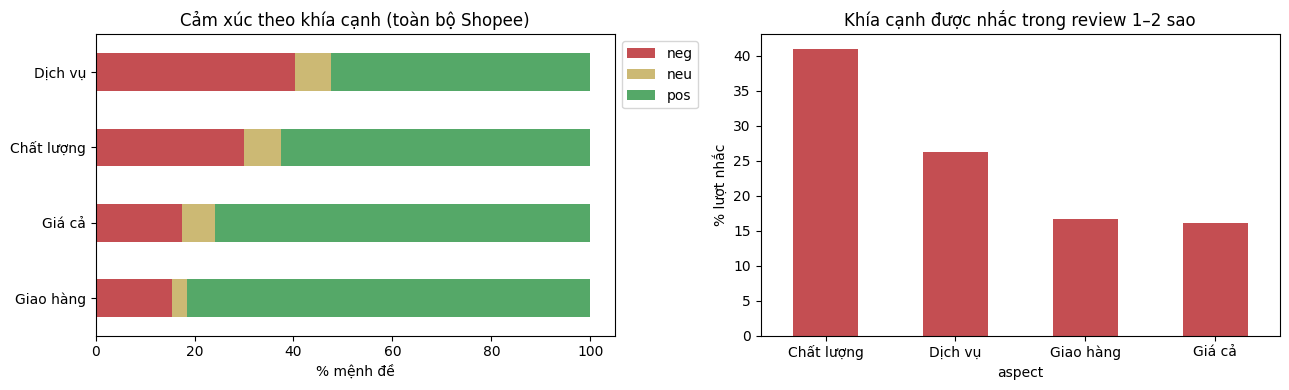

,n,neg_rate,% review nhắc tới
aspect,,,
Dịch vụ,718,0.404,0.282
Chất lượng,1452,0.300,0.570
Giá cả,746,0.176,0.293
Giao hàng,983,0.154,0.386


In [4]:
long = shp.melt(id_vars=["id", "category", "product", "rating"], value_vars=ASPECTS, var_name="aspect", value_name="sent")
long = long[long.sent != "none"]
long["aspect"] = long.aspect.map(ASP_VI)
summ = long.groupby("aspect").sent.agg(n="size", neg_rate=lambda s: (s == "neg").mean())
summ["% review nhắc tới"] = summ.n / len(shp)
summ = summ.sort_values("neg_rate", ascending=False)
summ.round(3).to_csv(f"{REP}/aspect_summary.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ct = pd.crosstab(long.aspect, long.sent, normalize="index")[["neg", "neu", "pos"]] * 100
ct.loc[summ.index[::-1]].plot.barh(stacked=True, ax=ax[0], color=["#C44E52", "#CCB974", "#55A868"])
ax[0].set(xlabel="% mệnh đề", ylabel="", title="Cảm xúc theo khía cạnh (toàn bộ Shopee)")
ax[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
low = long[long.rating <= 2].aspect.value_counts(normalize=True) * 100
low.plot.bar(ax=ax[1], color="#C44E52", rot=0)
ax[1].set(ylabel="% lượt nhắc", title="Khía cạnh được nhắc trong review 1–2 sao")
plt.tight_layout(); plt.savefig(f"{FIG}/absa_overview.png", bbox_inches="tight"); plt.show()
summ.round(3)

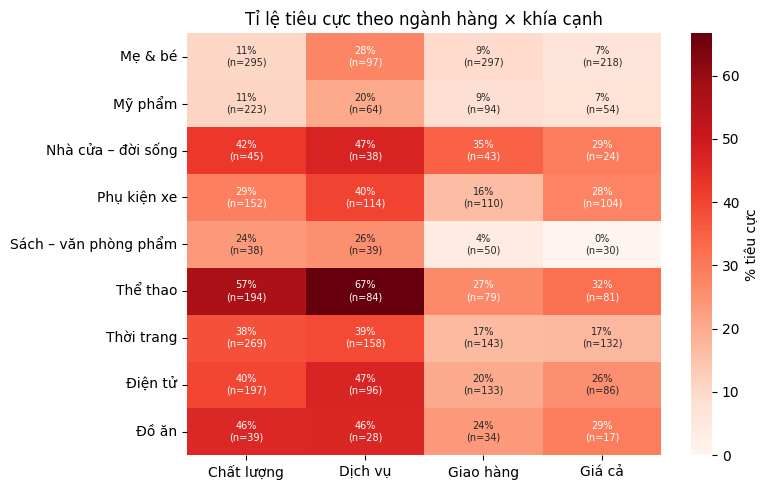

In [5]:
heat = (long.assign(is_neg=long.sent == "neg")
        .pivot_table(index="category", columns="aspect", values="is_neg", aggfunc="mean") * 100)
cnt = long.pivot_table(index="category", columns="aspect", values="id", aggfunc="size")
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=heat.round(0).astype("Int64").astype(str) + "%\n(n=" + cnt.fillna(0).astype(int).astype(str) + ")",
            fmt="", cmap="Reds", cbar_kws={"label": "% tiêu cực"}, annot_kws={"fontsize": 7})
plt.title("Tỉ lệ tiêu cực theo ngành hàng × khía cạnh"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.savefig(f"{FIG}/absa_heatmap.png", bbox_inches="tight"); plt.show()

### "Lời chê ẩn" trong review 4–5 sao

Chủ shop lọc theo sao sẽ bỏ qua những câu này. Đây là giá trị cộng thêm của mô hình so với cách làm hiện tại.

Chỉ xét **các câu của 10 sản phẩm giữ lại** (`in_train == False`). Với 22 sản phẩm còn lại, mô hình đã học đúng nhãn sao của chúng nên gần như không bao giờ đoán 4–5 sao là neg.

In [6]:
out = shp[~shp.in_train]
hidden = out[(out.rating >= 4) & (out.pred == "neg")].sort_values("p_neg", ascending=False)
print(f"{len(hidden)} review 4–5 sao bị mô hình đánh giá là tiêu cực "
      f"({len(hidden) / (out.rating >= 4).sum():.1%} số review 4–5 sao của 10 sản phẩm giữ lại)")
hidden[["category", "rating", "p_neg", "text_clean"] + ASPECTS].head(10)

17 review 4–5 sao bị mô hình đánh giá là tiêu cực (3.1% số review 4–5 sao của 10 sản phẩm giữ lại)


,category,rating,p_neg,text_clean,giao_hang,chat_luong,gia_ca,dich_vu
528,Mỹ phẩm,4,0.807,"nhẹ all dưỡng mụn Bôi lên mụn trứng cá, nó hết...",none,none,none,none
1400,Thời trang,4,0.794,"nhựa hơi to xanh mint, trắng Tay ai nhỏ thì ko...",none,none,none,none
2381,Mỹ phẩm,5,0.780,thơm mà lưu hương ko lâu,none,pos,none,none
522,Mỹ phẩm,4,0.602,k mui mụn giảm mụn Giảm mụn tuýp nhỏ. Sài dc t...,none,none,none,none
1405,Thời trang,4,0.568,đen 🖤 nhựa tụet vòi🥹 Gất đoẹp nhà,none,none,none,none
896,Mẹ & bé,4,0.521,người lớn và trẻ em 8/10 bông Dùng thay băng v...,none,pos,none,none
1024,Thời trang,4,0.484,da mềm có Giống như ảnh ạ Độ dính thì đỉnh lắm...,none,none,none,none
1231,Đồ ăn,4,0.480,n n Gu bà nàoooooo đâuu điểm danh nàoo 🧏🏻‍♀️🎁 ...,none,neg,none,none
1373,Thời trang,5,0.478,Đúng Nhựa Xanh Giá mềm mà đồng hồ nhìn ok lắm ...,neu,none,pos,none
1403,Thời trang,4,0.477,giống vs miêu tả.. chỉ có vụ báo thức thì ai k...,none,none,none,none


## 4. Ứng viên cho "Top 3 vấn đề cần cải thiện"

Xếp hạng các cặp (ngành hàng, khía cạnh) theo **số lượt chê** (ảnh hưởng tới nhiều khách) và **tỉ lệ chê**. Chọn 3 vấn đề. Với mỗi vấn đề cần: số liệu, 2–3 câu trích (ẩn danh, đã có sẵn bên dưới) và **một hành động cụ thể** (bạn tự đề xuất).

In [7]:
cand = (long.groupby(["category", "aspect"]).sent
        .agg(n_nhac="size", n_che=lambda s: (s == "neg").sum(), ti_le_che=lambda s: (s == "neg").mean())
        .query("n_nhac >= 15").sort_values("n_che", ascending=False).head(8))
cand.round(3).to_csv(f"{REP}/top_issue_candidates.csv", encoding="utf-8-sig")
cand.round(3)

,,n_nhac,n_che,ti_le_che
category,aspect,,,
Thể thao,Chất lượng,194,110,0.567
Thời trang,Chất lượng,269,102,0.379
Điện tử,Chất lượng,197,78,0.396
Thời trang,Dịch vụ,158,62,0.392
Thể thao,Dịch vụ,84,56,0.667
Phụ kiện xe,Dịch vụ,114,46,0.404
Điện tử,Dịch vụ,96,45,0.469
Phụ kiện xe,Chất lượng,152,44,0.289


In [8]:
key = {v: k for k, v in ASP_VI.items()}
for (cat, a), r in cand.head(3).iterrows():
    print(f"=== {cat} – {a}: {r.n_che} lượt chê / {r.n_nhac} lượt nhắc ({r.ti_le_che:.0%}) ===")
    q = shp[(shp.category == cat) & (shp[key[a]] == "neg")].sort_values("p_neg", ascending=False)
    for s in q.text_clean.head(3):
        print("  •", s[:200])
    print()

=== Thể thao – Chất lượng: 110.0 lượt chê / 194.0 lượt nhắc (57%) ===
  • Chất lượng quá tệ! Mới bơm lên đã bung chỉ may, sắp nổ! Không đáng tiền
  • chất lượng quá kém, mới đá vái cái mà đã rách, khâu không vớ vẩn.
  • Chất lượng kém. Bơm vào vẫn chưa căng mà đã rách

=== Thời trang – Chất lượng: 102.0 lượt chê / 269.0 lượt nhắc (38%) ===
  • Chất lượng thì kém nịt vào kh hiểu sao nó bị kẹt cứng không tháo ra được phải cắt đi làm ăn vậy dẹp mẹ shop đi
  • Chất lượng kém . Sai lầm khi đã mua
  • đen Thật sự là rất thất vọng về sản phẩm, đường may của balo bị lệch rất nhiều, nhắn tin để shop giải quyết thì k thấy nhắn lại thật sự rất thất vọng

=== Điện tử – Chất lượng: 78.0 lượt chê / 197.0 lượt nhắc (40%) ===
  • Chuột mới mua về đẽ bị lỗi đúc nhựa, cskh thì không thấy phản hồi hãng lớn mà làm ăn như này chán quá
  • sạc ko vào pin Sạc thử điện thoại 30p ko lên % nào
  • giao sai màu k hỏi khách hàng tự ý đổi và giao luôn kì vải ,sạc thì k lên pin thua shop luôn ạ đómg goid thì đẹp tệ

**Viết vào P6 (tự viết):** mỗi vấn đề gồm số liệu, câu trích, hành động. Ví dụ hành động: thêm bảng size theo chiều cao/cân nặng; đổi đơn vị vận chuyển hoặc thêm lớp chống sốc; mô tả rõ chất liệu và độ dày. Mỗi vấn đề nên có KPI để theo dõi: tỉ lệ chê khía cạnh đó giảm từ X% xuống Y% sau 1 tháng.

## 5. Word cloud theo khía cạnh × tiêu cực

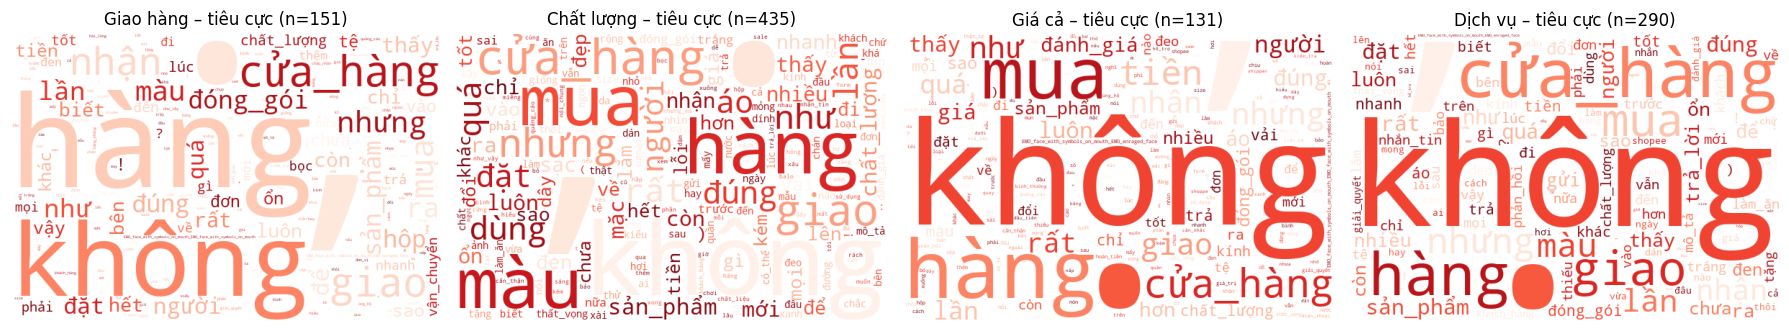

In [9]:
from wordcloud import WordCloud
from src.preprocess import remove_stopwords
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, a in zip(axes, ASPECTS):
    txt = " ".join(remove_stopwords(t) for t in shp[shp[a] == "neg"].text_prep)
    if txt.strip():
        wc = WordCloud(width=600, height=400, background_color="white", colormap="Reds",
                       regexp=r"[^\s]+", collocations=False, random_state=42).generate(txt)
        ax.imshow(wc)
    ax.axis("off"); ax.set_title(f"{ASP_VI[a]} – tiêu cực (n={(shp[a] == 'neg').sum()})")
plt.tight_layout(); plt.savefig(f"{FIG}/wordcloud_aspect_neg.png", bbox_inches="tight"); plt.show()